In [1]:
import numpy as np
import matplotlib.pyplot as plt



In [2]:
# Creation des données:

np.random.seed(42)


# la dimension (100,1)

X = np.random.rand(100,1) * 10

noise = np.random.rand(100,1)

y = 3*X + 5 + noise




In [ ]:
print(np.shape(X))
print(np.shape(y))


(100, 1)
(100, 1)


(100, 1)

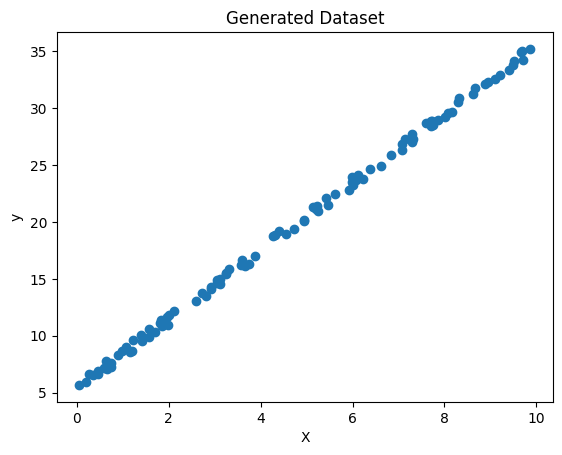

In [4]:
# on passe au partie visualisation : 

plt.scatter(X,y)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated Dataset")

plt.show()





In [6]:
import sys
sys.path.append("..")

from src.linear_regression import lineaireRegression

model = lineaireRegression(
    learning_rate=0.01,
    epochs=1000
)

model.fit(X, y)

print("Weights :", model.weights)
print("Bias :", model.bias)


Weights : [[2.99956042]]
Bias : 5.494641133816254


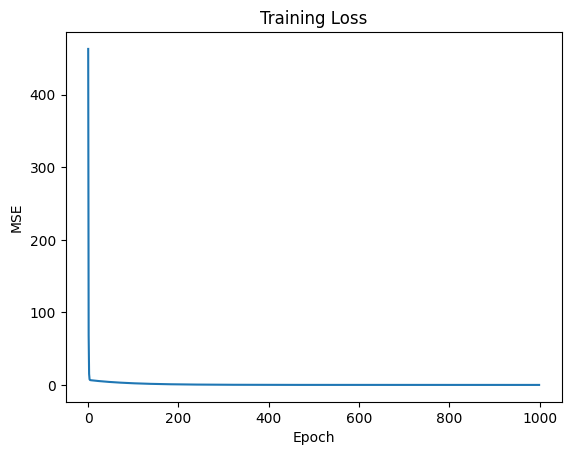

In [7]:
plt.plot(model.loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training Loss")

plt.show()


In [8]:
y_pred = model.prediction(X)

y_pred


array([[16.7291983 ],
       [34.01189118],
       [27.4512417 ],
       [23.45176408],
       [10.17451452],
       [10.17379102],
       [ 7.23689418],
       [31.47611798],
       [23.52544911],
       [26.73370593],
       [ 6.11208548],
       [34.58767318],
       [30.46426111],
       [11.86388106],
       [10.94859089],
       [10.99597022],
       [14.62057104],
       [21.23502736],
       [18.45109295],
       [14.23023516],
       [23.8475384 ],
       [ 9.67884377],
       [14.25769638],
       [16.48388598],
       [19.17473587],
       [29.04646851],
       [11.48397687],
       [20.91941382],
       [23.26447407],
       [ 6.88794933],
       [23.71831605],
       [10.60961526],
       [ 7.44590297],
       [33.95703615],
       [34.45935741],
       [29.74300803],
       [14.63171519],
       [ 8.42437521],
       [26.01862418],
       [18.69728113],
       [ 9.15525172],
       [20.34777174],
       [ 6.5261456 ],
       [32.77025601],
       [13.25690304],
       [25

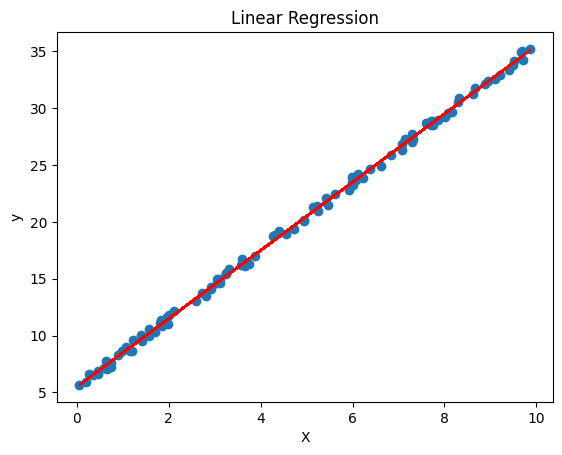

In [17]:



plt.scatter(X, y)
plt.plot(X, y_pred , color = "red")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression")

plt.show()



In [ ]:
# maitenant tout est bonne mais : 

# on teste le modele a partir des données ou j'ai fait l'apprentissage de modele 

# ce qui est pas bonne !

# on faire entrainement Train par 80% des données et 20% qui reste c'est pour le test

In [21]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("X_train : " , X_train.shape)
print("X_test : " , X_test.shape)
print("y_train : " , y_train.shape)
print("y_test : " , y_test.shape)



X_train :  (80, 1)
X_test :  (20, 1)
y_train :  (80, 1)
y_test :  (20, 1)


In [26]:
# alors maintenant le fait d'entrainer le module sur Train seulement !

model = lineaireRegression(
    learning_rate=0.01,
    epochs=1000
)
model.fit(X_train,y_train)

y_prediction = model.prediction(X_test)

y_prediction


array([[ 7.416114  ],
       [32.33249418],
       [28.65821523],
       [25.3694036 ],
       [13.26766913],
       [18.70411205],
       [14.26773858],
       [31.3816042 ],
       [ 6.12801961],
       [16.73745279],
       [18.45810195],
       [23.72151512],
       [29.95358737],
       [33.95282928],
       [ 9.09572876],
       [10.18751019],
       [28.62900797],
       [ 7.73042943],
       [30.46258066],
       [10.62229621]])

In [28]:
from src.metrics import mse,mae,r2_score
mse_value = mse(y_test, y_prediction)
mae_value = mae(y_test, y_prediction)
r2_value = r2_score(y_test, y_prediction)

print("MSE :", mse_value)
print("MAE :", mae_value)
print("R²  :", r2_value)





MSE : 0.09449236776019175
MAE : 0.2736743012001183
R²  : 0.9989414967051978


In [29]:
from src.evaluation import evaluation_model

results = evaluation_model(y_test,y_pred)

results



{'MSE': np.float64(0.09449236776019175),
 'MAE': np.float64(0.2736743012001183),
 'R2': np.float64(0.9989414967051978)}

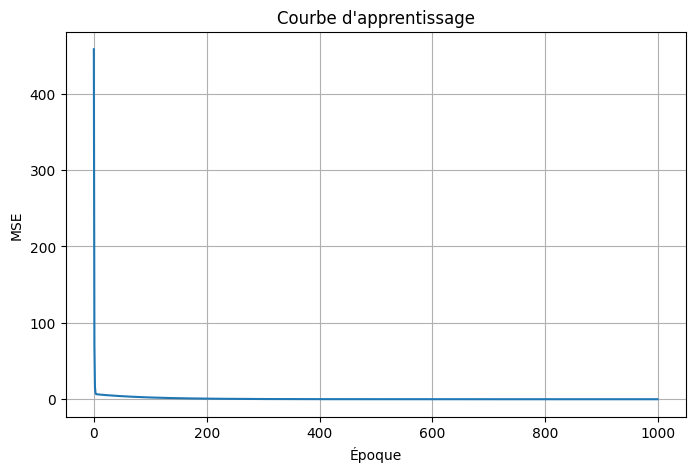

In [32]:
# on passe maintenant au jour 3 : 


import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(model.loss_history)



plt.xlabel("Époque")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage")
plt.grid(True)
plt.show()








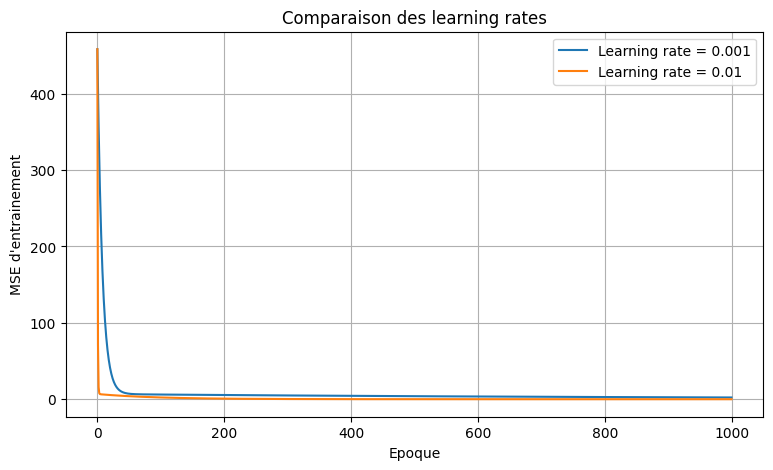

In [ ]:
# Etudier l'effet du learning rate : 

learning_rate = [0.001,0.01]

plt.figure(figsize=(9,5))

for lr in learning_rate : 
    experiment = lineaireRegression(
        learning_rate=lr,
        epochs=1000
    )
    experiment.fit(X_train,y_train)

    plt.plot(
        experiment.loss_history,
        label = f"Learning rate = {lr}"
    )

plt.xlabel("Epoque")
plt.ylabel("MSE d'entrainement")

plt.title("Comparaison des learning rates")
plt.legend()
plt.grid(True)
plt.show()



# 0.001 : apprentissage généralement plus lent.
# 0.01 : apprentissage potentiellement plus rapide et stable.
# 0.1 : risque de divergence avec les données utilisées, car les valeurs de X peuvent aller jusqu’à 10.



In [ ]:
# on passe maintenant au test le nombre d'époques : 

epochs_list = [10,100,1000]

for epochs in epochs_list :
    experiment = lineaireRegression(
        learning_rate=0.01,
        epochs= epochs
    )

    experiment.fit(X_train,y_train)

    predictions = experiment.prediction(X_test)

    print(f"\nEpoques :  {epochs}")
    print("MSE Test " , mse(y_test,predictions))



# L’objectif est de comprendre qu’un plus grand nombre d’époques peut améliorer l’apprentissage,
# mais qu’il ne garantit pas systématiquement de meilleures performances sur le test.









Epoques :  10
MSE Test  6.525143137708947

Epoques :  100
MSE Test  2.441920617932206

Epoques :  1000
MSE Test  0.09449236776019175


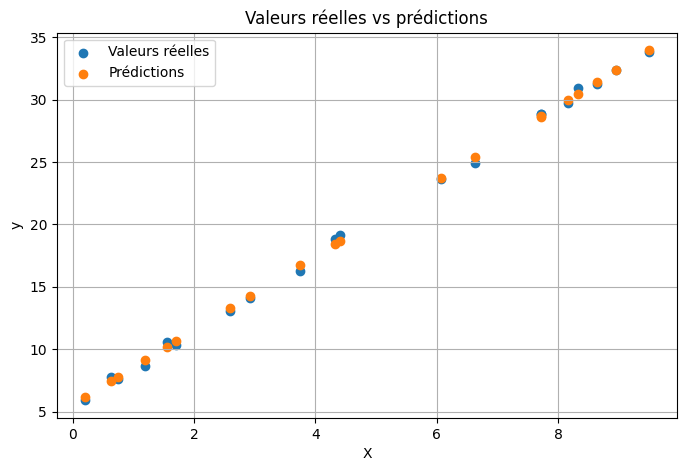

In [39]:

# visualiser les predictions et les erreurs  : 

y_pre = model.prediction(X_test)

plt.figure(figsize=(8,5))

plt.scatter(
    X_test[:, 0],
    y_test[:, 0],
    label="Valeurs réelles"
)

plt.scatter(
    X_test[:, 0],
    y_pre[:, 0],
    label="Prédictions"
)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Valeurs réelles vs prédictions")
plt.legend()
plt.grid(True)
plt.show()






